In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

# Algorithms to use
from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.tree import DecisionTreeClassifier
# ensamblamiento de los arboles
from sklearn.ensemble import BaggingClassifier

from sklearn.ensemble import RandomForestClassifier

# Metricas para evaluar el modelo
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve,recall_score, mean_squared_error, mean_absolute_error, r2_score
from sklearn import tree

from sklearn.model_selection import GridSearchCV

import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression
#from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
ruta = '/content/drive/MyDrive/mineria/new_online_shoppers_intention.csv'
df = pd.read_csv(ruta)
print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (12205, 22)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total,Trimestre
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,1,1,Returning_Visitor,False,False,0.000000,1,0.000000,1
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,2,1,2,Returning_Visitor,False,False,21.333333,2,64.000000,1
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,9,3,Returning_Visitor,False,False,0.000000,1,0.000000,1
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,2,2,4,Returning_Visitor,False,False,0.888889,2,2.666667,1
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,3,1,4,Returning_Visitor,True,False,57.045455,10,627.500000,1


In [ ]:
#df.info()

In [ ]:
numericas = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration','ProductRelated', 'ProductRelated_Duration','BounceRates','ExitRates',
             'PageValues','Avg_Tiempo_Producto', 'Total_paginasVisitadas', 'Duracion_Total']
categoricas = ['Month', 'OperatingSystems','Browser', 'Region','TrafficType','VisitorType','Weekend', 'Revenue','SpecialDay', 'Trimestre']

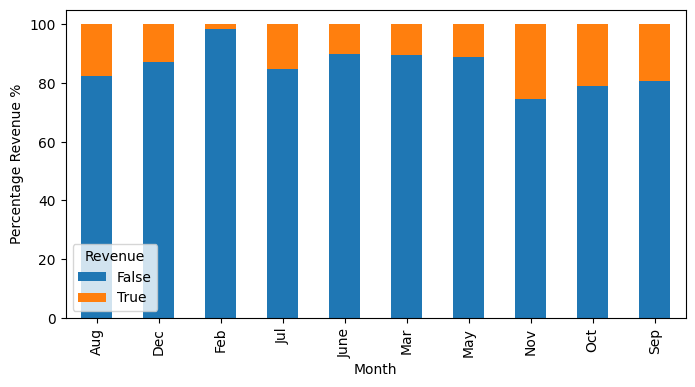

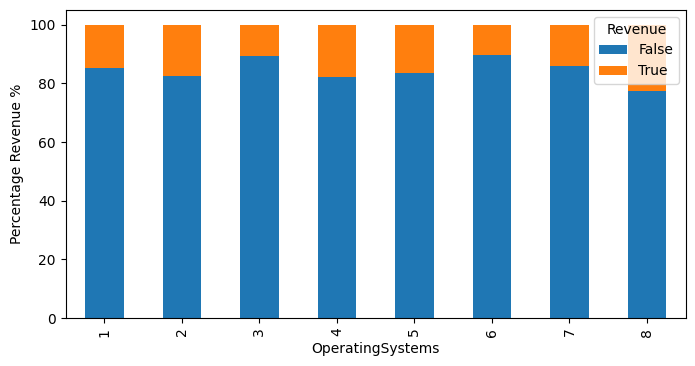

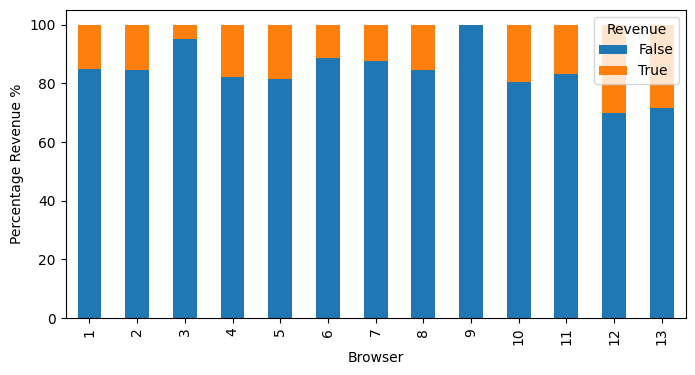

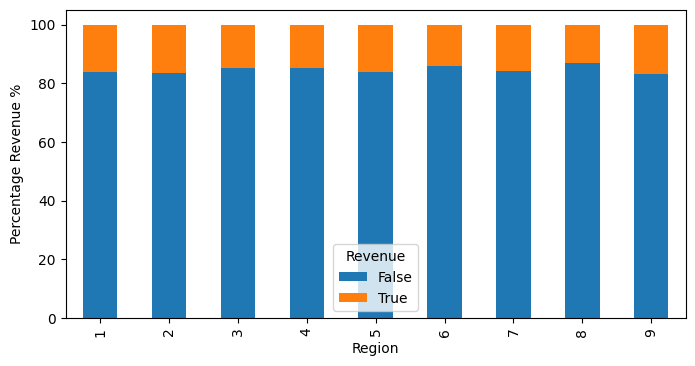

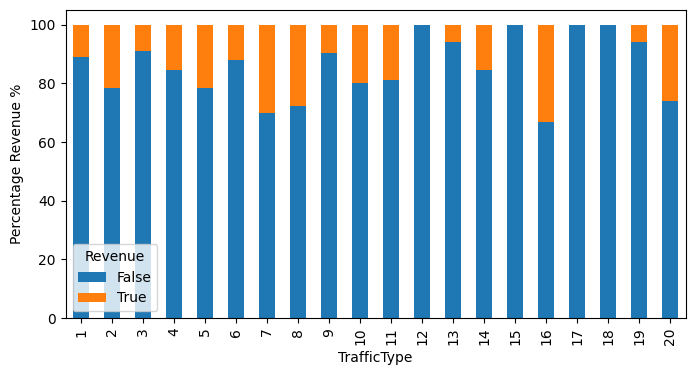

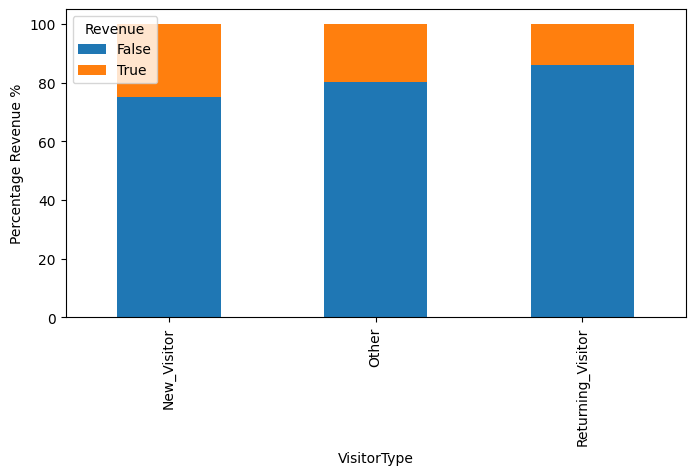

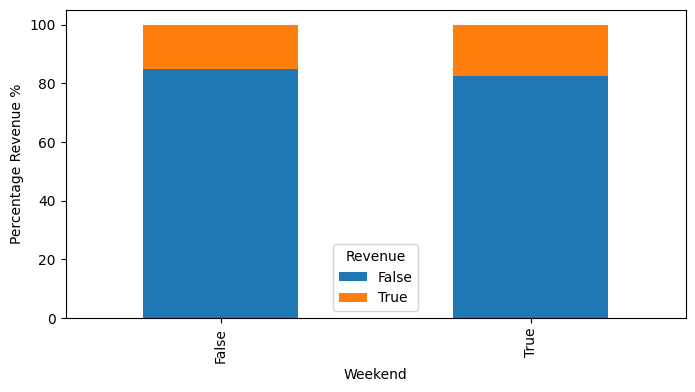

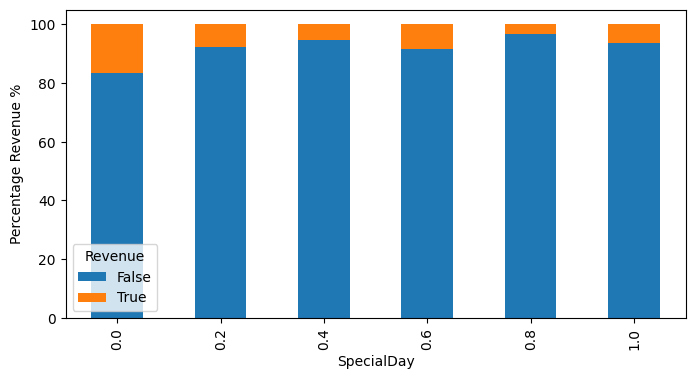

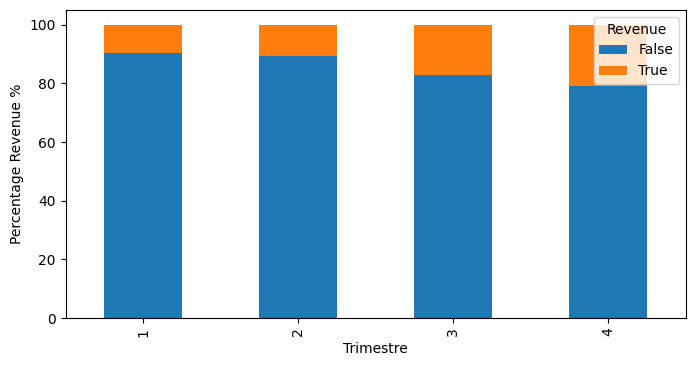

In [ ]:
for i in categoricas:
    if i!='Revenue':
        (pd.crosstab(df[i],df['Revenue'],normalize='index')*100).plot(kind='bar',figsize=(8,4),stacked=True)
        plt.ylabel('Percentage Revenue %')

In [ ]:
# promedio de las variables numericas por attrition
df.groupby(['Revenue'])[numericas].mean()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total
Revenue,,,,,,,,,,,,
False,2.143440,74.635276,0.457318,30.603289,29.050403,1082.976881,0.023197,0.045526,1.999985,33.742170,31.651161,1188.215446
True,3.393606,119.483244,0.786164,57.611427,48.210168,1876.209615,0.005117,0.019555,27.264518,39.779632,52.389937,2053.304285


**Observaciones:**

- Las sesiones que terminan en compra presentan medias más altas en todas las variables de navegación: 48.21 páginas de producto frente a 29.05, 1,876.21 s frente a 1,082.98 s y 52.39 páginas totales frente a 31.65.
- También visitan más páginas administrativas e informativas (3.39 frente a 2.14 y 0.79 frente a 0.46).
- Las tasas de rebote y salida son menores en quienes compran (0.0051 y 0.0196) que en quienes no (0.0232 y 0.0455).
- `PageValues` muestra la diferencia más marcada: 27.26 en compradores frente a 2.00 en no compradores. Como su disponibilidad antes de la compra no está confirmada, se usa en los experimentos de este cuaderno con esa reserva.

In [ ]:
to_get_dummies_for = ['Month', 'OperatingSystems','Browser', 'Region','TrafficType','VisitorType','SpecialDay', 'Trimestre']
df = pd.get_dummies(data = df, columns = to_get_dummies_for, drop_first = True)

# Mapear variables
dict_Weekend = {'True': 1, 'False':0}
dict_Revenue = {'True': 1, 'False': 0}

# 'Weekend', 'Revenue'
#df['Weekend'] = df.Weekend.map(dict_Weekend)
#df['Revenue'] = df.Revenue.map(dict_Revenue)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 79 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Administrative                 12205 non-null  int64  
 1   Administrative_Duration        12205 non-null  float64
 2   Informational                  12205 non-null  int64  
 3   Informational_Duration         12205 non-null  float64
 4   ProductRelated                 12205 non-null  int64  
 5   ProductRelated_Duration        12205 non-null  float64
 6   BounceRates                    12205 non-null  float64
 7   ExitRates                      12205 non-null  float64
 8   PageValues                     12205 non-null  float64
 9   Weekend                        12205 non-null  bool   
 10  Revenue                        12205 non-null  bool   
 11  Avg_Tiempo_Producto            12205 non-null  float64
 12  Total_paginasVisitadas         12205 non-null 

In [ ]:
df['Revenue']

,Revenue
0,False
1,False
2,False
3,False
4,False
...,...
12200,False
12201,False
12202,False
12203,False


In [ ]:
# Separar la variable objetivos de las demas

Y= df.Revenue
X= df.drop(columns = ['Revenue'])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 1, stratify = Y)

In [ ]:
print(y_train.value_counts(normalize=True))

Revenue
False    0.843712
True     0.156288
Name: proportion, dtype: float64


In [ ]:
print(y_test.value_counts(normalize=True))

Revenue
False    0.843507
True     0.156493
Name: proportion, dtype: float64


**Observaciones:**

- Se usaron 9,764 sesiones para entrenamiento y 2,441 para prueba (80/20, `random_state=1`, con `stratify=Y`).
- La estratificación conservó la proporción de compras: 15.63 % en entrenamiento y 15.65 % en prueba, equivalentes a 382 compras en el conjunto de prueba.
- Las variables categóricas se codificaron con `pd.get_dummies(drop_first=True)` para `Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`, `SpecialDay` y `Trimestre`, dando lugar a 78 predictoras.
- `Weekend` permaneció como booleano: el mapeo a 0/1 está comentado en el código, pero `StandardScaler` lo convierte a escala numérica sin problema.

In [ ]:
X_train

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Weekend,...,VisitorType_Other,VisitorType_Returning_Visitor,SpecialDay_0.2,SpecialDay_0.4,SpecialDay_0.6,SpecialDay_0.8,SpecialDay_1.0,Trimestre_2,Trimestre_3,Trimestre_4
3904,0,0.000000,0,0.000000,7,380.000000,0.014286,0.074286,0.000000,True,...,False,True,False,False,False,False,False,True,False,False
10800,0,0.000000,0,0.000000,22,348.500000,0.004545,0.022727,0.000000,True,...,False,True,False,False,False,False,False,False,False,True
9042,0,0.000000,0,0.000000,8,650.250000,0.000000,0.025000,0.000000,False,...,False,True,False,False,False,False,False,False,False,True
11598,5,107.666667,10,505.166667,281,14988.591510,0.008499,0.029697,0.000000,False,...,False,True,False,False,False,False,False,False,False,True
3650,0,0.000000,0,0.000000,4,81.000000,0.000000,0.050000,0.000000,False,...,False,True,False,True,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4011,5,210.777778,3,215.000000,33,1887.694444,0.008571,0.032381,11.694857,False,...,False,True,False,False,False,False,False,True,False,False
2844,0,0.000000,0,0.000000,23,996.438095,0.000000,0.019928,0.000000,False,...,False,True,False,False,False,True,False,True,False,False
11885,5,29.000000,0,0.000000,8,233.500000,0.000000,0.027778,0.000000,False,...,False,True,False,False,False,False,False,False,False,True
7921,1,65.500000,1,38.500000,131,3902.664774,0.008889,0.022870,0.000000,False,...,False,True,False,False,False,False,False,False,False,True


In [ ]:
X_test

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Weekend,...,VisitorType_Other,VisitorType_Returning_Visitor,SpecialDay_0.2,SpecialDay_0.4,SpecialDay_0.6,SpecialDay_0.8,SpecialDay_1.0,Trimestre_2,Trimestre_3,Trimestre_4
5402,0,0.000000,0,0.0,1,0.000000,0.100000,0.200000,0.000000,True,...,False,False,False,False,False,False,False,False,True,False
6718,5,69.900000,0,0.0,62,1846.666667,0.006061,0.018939,0.000000,False,...,False,True,False,False,False,False,False,False,True,False
4719,0,0.000000,0,0.0,10,428.666667,0.000000,0.022222,36.256000,False,...,False,False,False,True,False,False,False,True,False,False
5991,4,102.300000,0,0.0,59,1684.496667,0.000000,0.009524,25.854420,False,...,False,True,False,False,False,False,False,False,False,True
11415,2,15.000000,0,0.0,35,1776.083333,0.000000,0.011429,0.000000,False,...,False,True,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3575,0,0.000000,0,0.0,3,108.000000,0.000000,0.066667,0.000000,False,...,False,True,False,False,False,False,False,True,False,False
7704,4,53.200000,0,0.0,14,496.966667,0.000000,0.009804,0.000000,False,...,False,True,False,False,False,False,False,False,False,True
6026,3,82.533333,1,0.0,19,668.700000,0.022727,0.032424,11.595226,False,...,False,True,False,False,False,False,False,False,False,True
2300,0,0.000000,0,0.0,3,133.500000,0.100000,0.155556,0.000000,False,...,False,True,False,True,False,False,False,True,False,False


In [ ]:
y_train

,Revenue
3904,False
10800,True
9042,False
11598,False
3650,False
...,...
4011,True
2844,False
11885,False
7921,False


In [ ]:
y_test

,Revenue
5402,False
6718,False
4719,True
5991,False
11415,False
...,...
3575,False
7704,False
6026,False
2300,False


In [ ]:
sc=StandardScaler()


X_train_scaled=sc.fit_transform(X_train)
X_train_scaled=pd.DataFrame(X_train_scaled, columns=X.columns)

X_test_scaled=sc.transform(X_test)
X_test_scaled=pd.DataFrame(X_test_scaled, columns=X.columns)

**Observaciones:**

- El escalador se ajustó solo con `X_train` (`fit_transform`) y se aplicó a prueba con `transform`, evitando que información de prueba influya en la estandarización.
- A diferencia del informe, aquí se escalan las 78 predictoras, incluidas las variables dummy. Esto no cambia el árbol ni el SVM, pero sí es relevante para la regresión logística, que optimiza sobre distancias y regularización.

In [ ]:
X_train_scaled

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Weekend,...,VisitorType_Other,VisitorType_Returning_Visitor,SpecialDay_0.2,SpecialDay_0.4,SpecialDay_0.6,SpecialDay_0.8,SpecialDay_1.0,Trimestre_2,Trimestre_3,Trimestre_4
0,-0.699170,-0.464096,-0.396188,-0.243806,-0.556933,-0.427435,-0.136130,0.709434,-0.313824,1.801449,...,-0.07994,0.412871,-0.122347,-0.140874,-0.170874,-0.164087,-0.112485,1.535083,-0.348974,-0.862486
1,-0.699170,-0.464096,-0.396188,-0.243806,-0.226587,-0.443673,-0.350789,-0.405878,-0.313824,1.801449,...,-0.07994,0.412871,-0.122347,-0.140874,-0.170874,-0.164087,-0.112485,-0.651431,-0.348974,1.159439
2,-0.699170,-0.464096,-0.396188,-0.243806,-0.534910,-0.288124,-0.450963,-0.356714,-0.313824,-0.555109,...,-0.07994,0.412871,-0.122347,-0.140874,-0.170874,-0.164087,-0.112485,-0.651431,-0.348974,1.159439
3,0.795291,0.150730,7.596332,3.414440,5.477388,7.103150,-0.263661,-0.255105,-0.313824,-0.555109,...,-0.07994,0.412871,-0.122347,-0.140874,-0.170874,-0.164087,-0.112485,-0.651431,-0.348974,1.159439
4,-0.699170,-0.464096,-0.396188,-0.243806,-0.623002,-0.581567,-0.450963,0.184086,-0.313824,-0.555109,...,-0.07994,0.412871,-0.122347,7.098554,-0.170874,-0.164087,-0.112485,1.535083,-0.348974,-0.862486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9759,0.795291,0.739542,2.001568,1.313151,0.015667,0.349766,-0.262063,-0.197049,0.294231,-0.555109,...,-0.07994,0.412871,-0.122347,-0.140874,-0.170874,-0.164087,-0.112485,1.535083,-0.348974,-0.862486
9760,-0.699170,-0.464096,-0.396188,-0.243806,-0.204564,-0.109668,-0.450963,-0.466442,-0.313824,-0.555109,...,-0.07994,0.412871,-0.122347,-0.140874,-0.170874,6.094311,-0.112485,1.535083,-0.348974,-0.862486
9761,0.795291,-0.298493,-0.396188,-0.243806,-0.534910,-0.502955,-0.450963,-0.296625,-0.313824,-0.555109,...,-0.07994,0.412871,-0.122347,-0.140874,-0.170874,-0.164087,-0.112485,-0.651431,-0.348974,1.159439
9762,-0.400278,-0.090061,0.403064,0.034998,2.173928,1.388464,-0.255067,-0.402782,-0.313824,-0.555109,...,-0.07994,0.412871,-0.122347,-0.140874,-0.170874,-0.164087,-0.112485,-0.651431,-0.348974,1.159439


<Axes: >

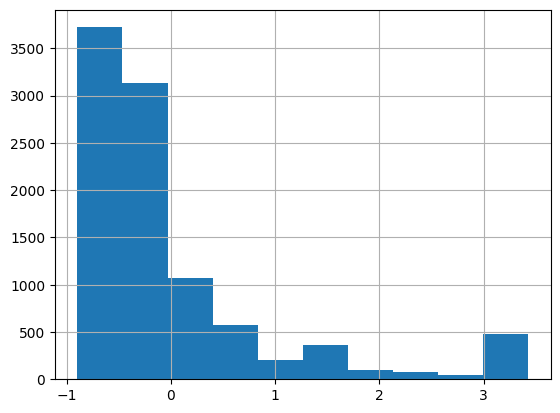

In [ ]:
X_train_scaled['ExitRates'].hist()

## Histograma después del escalado.

El histograma permite observar cómo se distribuye ExitRates tras aplicar StandardScaler. El escalado cambia unidades, centro y dispersión, pero no elimina por sí solo la asimetría ni los valores extremos.

In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9764 entries, 3904 to 4925
Data columns (total 78 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Administrative                 9764 non-null   int64  
 1   Administrative_Duration        9764 non-null   float64
 2   Informational                  9764 non-null   int64  
 3   Informational_Duration         9764 non-null   float64
 4   ProductRelated                 9764 non-null   int64  
 5   ProductRelated_Duration        9764 non-null   float64
 6   BounceRates                    9764 non-null   float64
 7   ExitRates                      9764 non-null   float64
 8   PageValues                     9764 non-null   float64
 9   Weekend                        9764 non-null   bool   
 10  Avg_Tiempo_Producto            9764 non-null   float64
 11  Total_paginasVisitadas         9764 non-null   int64  
 12  Duracion_Total                 9764 non-null   flo

In [ ]:
def metrics_score(actual, predicted, labels=None):
    print("\nReporte de clasificación:")
    # actual es y que conozco
    print(metrics.classification_report(actual, predicted, target_names=labels if labels is not None else None))

    cm = metrics.confusion_matrix(actual, predicted)
    print("\nMatriz de confusión:")
    print(cm)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=labels if labels is not None else sorted(set(actual)),
                yticklabels=labels if labels is not None else sorted(set(actual)),
                cmap="Blues")
    plt.ylabel('Valor Real')
    plt.xlabel('Valor Predicho')
    plt.title('Matriz de Confusión')
    plt.show()

# Regresion logistica


In [ ]:
# La regresion regresa un numero
lg = LogisticRegression()
# x variables , y la etiqueta
lg.fit(X_train_scaled, y_train)

LogisticRegression()

In [ ]:
y_prob_train = lg.predict_proba(X_train_scaled)
y_prob_train_df = pd.DataFrame(y_prob_train, columns = lg.classes_)

y_prob_train_df

,False,True
0,0.976505,0.023495
1,0.847543,0.152457
2,0.986781,0.013219
3,0.800290,0.199710
4,0.977433,0.022567
...,...,...
9759,0.946875,0.053125
9760,0.961876,0.038124
9761,0.952417,0.047583
9762,0.841921,0.158079


In [ ]:
# Calcular probabilidades sobre test
y_prob_test = lg.predict_proba(X_test_scaled)
y_prob_test_df = pd.DataFrame(y_prob_test, columns = lg.classes_)

y_prob_test_df

,False,True
0,0.991968,0.008032
1,0.899073,0.100927
2,0.530660,0.469340
3,0.337954,0.662046
4,0.941677,0.058323
...,...,...
2436,0.989517,0.010483
2437,0.881594,0.118406
2438,0.730472,0.269528
2439,0.996952,0.003048


## Probabilidades en prueba.

La misma función genera probabilidades para sesiones no utilizadas en el ajuste. La columna True se emplea más adelante para analizar cómo cambia la clasificación al modificar el umbral de decisión.

In [ ]:
Y_pred_test = lg.predict(X_test_scaled)
Y_pred_test_df = pd.DataFrame(Y_pred_test, columns = ['Prediccion'])

Y_pred_test_df

,Prediccion
0,False
1,False
2,False
3,True
4,False
...,...
2436,False
2437,False
2438,False
2439,False


## Predicciones de clase con umbral predeterminado.

predict(X_test_scaled) convierte las probabilidades en las etiquetas False y True. En la regresión logística binaria de este notebook se emplea el criterio predeterminado equivalente a 0.50 para la clase positiva.

In [ ]:
pd.DataFrame({'Actual': y_test, 'Predicted':Y_pred_test,
              'Prob_0': y_prob_test[:, 0], 'Prob_1': y_prob_test[:, 1]
              }
             ).head(10)

,Actual,Predicted,Prob_0,Prob_1
5402,False,False,0.991968,0.008032
6718,False,False,0.899073,0.100927
4719,True,False,0.530660,0.469340
5991,False,True,0.337954,0.662046
11415,False,False,0.941677,0.058323
6611,False,False,0.967044,0.032956
11711,False,False,0.962525,0.037475
4942,False,False,0.914845,0.085155
9227,False,False,0.772051,0.227949
3062,False,False,0.935633,0.064367



Reporte de clasificación:
              precision    recall  f1-score   support

  No Revenue       0.89      0.97      0.93      2059
     Revenue       0.70      0.37      0.48       382

    accuracy                           0.88      2441
   macro avg       0.80      0.67      0.71      2441
weighted avg       0.86      0.88      0.86      2441


Matriz de confusión:
[[2000   59]
 [ 241  141]]


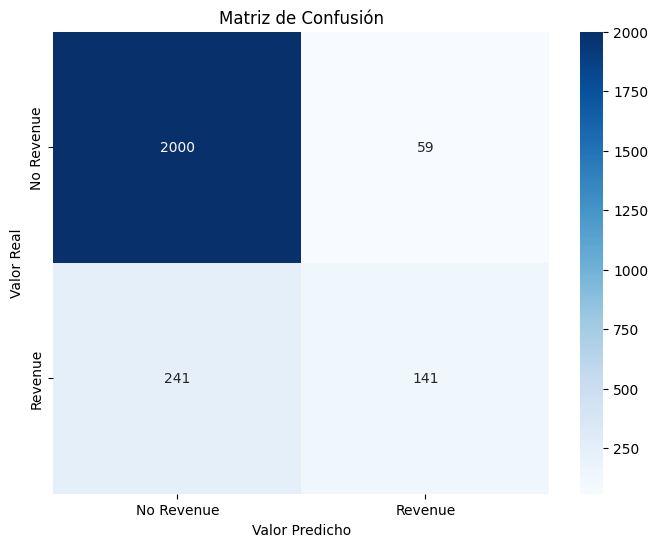

In [ ]:
# Evaluar el modelo
## supprt es cuantos ejemplos vio
# en este caso queriamos evitar los falsos positivos y se en recal se ve si nos evitaroa
metrics_score(y_test, Y_pred_test, labels=['No Revenue', 'Revenue'])

**Observaciones:**

- Clasificó correctamente 2,141 de 2,441 sesiones (accuracy 88 %), pero solo detectó 141 de las 382 compras reales: **recall 37 %**, precisión 70 % y F1 0.48.
- Dejó pasar 241 compras (falsos negativos) y generó 59 falsos positivos.
- El accuracy alto se debe sobre todo a la clase mayoritaria: un predictor que siempre dijera "no compra" ya alcanzaría el 84.35 %. Por eso el recall es el criterio principal.

In [ ]:
lg.coef_

array([[ 3.25661874e-02, -3.09601028e-02,  8.96814050e-03,
         3.77506202e-02,  7.41853103e-02,  2.60786096e-02,
        -4.85157906e-02, -7.84687077e-01,  1.56448714e+00,
         5.43505117e-02,  4.52731979e-02,  7.35352767e-02,
         2.44160083e-02, -1.93569878e-01, -1.08674723e-01,
         3.05000542e-02,  2.28346969e-02, -1.08174717e-01,
        -5.69670234e-02,  2.41534597e-01,  1.28086138e-02,
        -2.33458381e-02,  6.23484151e-02, -3.57616727e-02,
        -1.99032319e-02,  1.06025063e-03, -7.92417032e-02,
        -7.45701778e-02,  4.14328034e-02, -2.76540361e-02,
        -6.95848641e-02, -2.33814477e-02,  1.96976040e-02,
        -3.83425260e-02,  1.85869268e-02,  2.14769338e-02,
         0.00000000e+00,  4.09631489e-02,  1.06025063e-03,
         4.96000595e-02,  8.23091247e-02, -5.27901248e-03,
        -3.33253573e-02, -4.49090002e-02, -4.42779920e-02,
         2.20236578e-02, -2.99421533e-02,  6.12774195e-04,
        -3.19916143e-02,  8.73893460e-02, -9.54606473e-0

In [ ]:
lg.coef_df = pd.DataFrame(lg.coef_, columns = X.columns).T.sort_values(by=0, ascending = False)
lg.coef_df

,0
PageValues,1.564487
Month_Nov,0.241535
TrafficType_8,0.120691
Trimestre_3,0.107455
TrafficType_2,0.087389
...,...
TrafficType_13,-0.192519
Month_Dec,-0.193570
VisitorType_Other,-0.203794
TrafficType_15,-0.231742


In [ ]:
# Razon de probabilidad
# odd > 1 aumenta la probalilidad de deserciom
# odd > 1 disminiue la probalilidad de deserciom
# odd = 1 sin efecto
lg_odd_ratio = pd.DataFrame(np.exp(lg.coef_), columns = X.columns).T.sort_values(by=0, ascending = False)
lg_odd_ratio

,0
PageValues,4.780223
Month_Nov,1.273202
TrafficType_8,1.128276
Trimestre_3,1.113441
TrafficType_2,1.091321
...,...
TrafficType_13,0.824879
Month_Dec,0.824012
VisitorType_Other,0.815630
TrafficType_15,0.793151


**Observaciones:**

- `PageValues` es el predictor con mayor peso (**+1.5645**; razón de probabilidades 4.78), seguido de `Month_Nov` (+0.2415; odds 1.27).
- `ExitRates` tiene el coeficiente más negativo (**−0.7847**; odds 0.46): a mayor tasa de salida, menor probabilidad estimada de compra.
- Los coeficientes describen asociaciones condicionadas al resto de variables, no relaciones causales. En particular, el peso de `PageValues` debe interpretarse con cautela mientras no se confirme cuándo está disponible esa información en una aplicación real.

(0.0, 1.0)

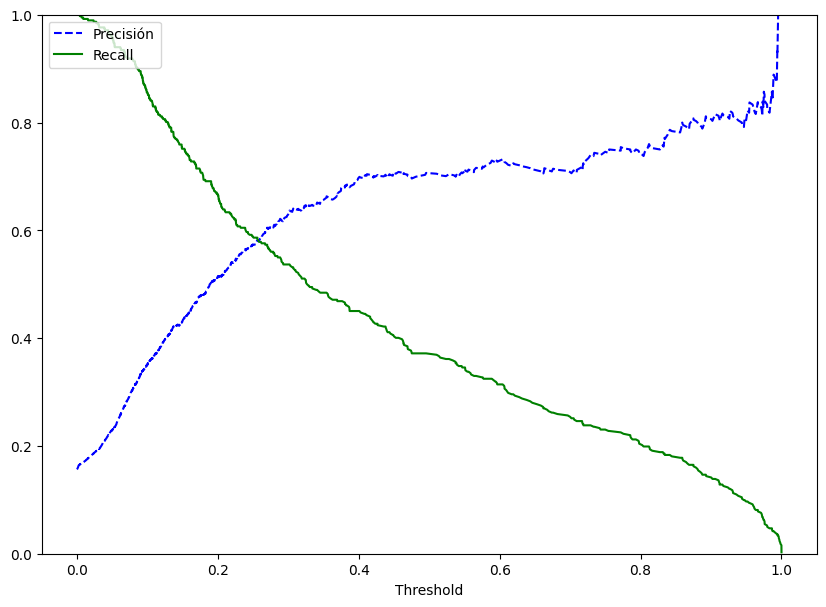

In [ ]:
#Curva Precision Recall
y_scores_lg = y_prob_test
preciscions_lg, recalls_lg, thresholds_lg = precision_recall_curve(y_test, y_scores_lg[:,1])

#Graficar la curva Precision Recall
plt.figure(figsize=(10,7))
plt.plot(thresholds_lg, preciscions_lg[:-1], "b--", label="Precisión")
plt.plot(thresholds_lg, recalls_lg[:-1], "g-", label="Recall")
plt.xlabel("Threshold")
plt.legend(loc="upper left")
plt.ylim([0,1])

In [ ]:
import numpy as np

# Se debe de igualar sus tamaños:
precision_vals = preciscions_lg[:-1]
recall_vals = recalls_lg[:-1]

# Calculamos la diferencia absoluta entre precisión y recall en cada punto
diferencias = np.abs(precision_vals - recall_vals)

# Encontramos el índice donde la diferencia es la más pequeña (el cruce)
indice_cruce = np.argmin(diferencias)

# Extraemos el umbral (threshold) y el valor exacto en ese cruce
umbral_cruce = thresholds_lg[indice_cruce]
valor_cruce = precision_vals[indice_cruce] # En este punto, precisión y recall son iguales

print(f"El umbral exacto del cruce es: {umbral_cruce:.4f}")
print(f"El valor exacto de Precisión/Recall es: {valor_cruce:.4f}")

El umbral exacto del cruce es: 0.2575
El valor exacto de Precisión/Recall es: 0.5812


**Observaciones:**

- La curva precisión-recall indica un punto de cruce en **0.2575**, con precisión y recall cercanos a 0.5812.
- Se adoptó finalmente **0.25** por ser un valor cercano y más sencillo de comunicar.
- Cambiar el umbral no vuelve a entrenar el modelo: solo modifica cómo se convierten las probabilidades en clases.


Reporte de clasificación:
              precision    recall  f1-score   support

  No Revenue       0.92      0.92      0.92      2059
     Revenue       0.57      0.59      0.58       382

    accuracy                           0.87      2441
   macro avg       0.75      0.75      0.75      2441
weighted avg       0.87      0.87      0.87      2441


Matriz de confusión:
[[1892  167]
 [ 158  224]]


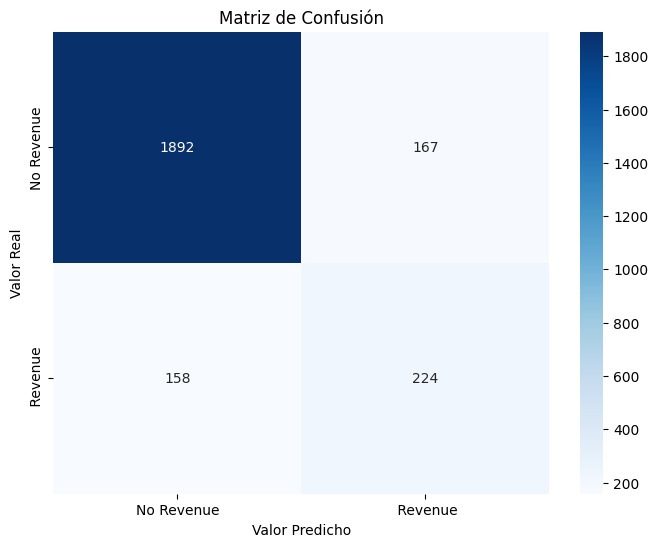

In [ ]:
# Para cada probabilidad me dice si esta cumpliendo con el elementonoptimo
optimo = 0.25
# al bajar el umbral aumentan ls FP y vajan

y_pred_test_optimo = lg.predict_proba(X_test_scaled)[:,1] > optimo
#y_pred_test_optimo
metrics_score(y_test, y_pred_test_optimo, labels=["No Revenue", " Revenue"])

**Observaciones:**

- Al bajar el umbral de 0.50 a 0.25, el recall de compra sube de 37 % a **59 %** (TP de 141 a 224) y el F1 de 0.48 a **0.58**.
- El costo es un aumento de falsos positivos (de 59 a 167) y un accuracy ligeramente menor (de 88 % a 87 %).
- Esta configuración equilibra mejor ambas clases, pero sigue detectando menos compras que el árbol con pesos (318). La elección depende del costo relativo de perder una compra frente a generar una falsa alarma.

In [ ]:
dt = DecisionTreeClassifier(
    class_weight={0:0.17, 1:0.83},
    criterion='gini',
    min_samples_leaf=10,
    min_impurity_decrease=0.001,
    random_state=42
    )
dt.fit(X_train_scaled, y_train)

DecisionTreeClassifier(class_weight={0: 0.17, 1: 0.83},
                       min_impurity_decrease=0.001, min_samples_leaf=10,
                       random_state=42)

In [ ]:
print("Profundidad del arbol", dt.get_depth())
print("numero de nodos", dt.get_n_leaves())

Profundidad del arbol 6
numero de nodos 18



Reporte de clasificación:
              precision    recall  f1-score   support

  No Revenue       0.97      0.86      0.91      2059
     Revenue       0.52      0.83      0.64       382

    accuracy                           0.85      2441
   macro avg       0.74      0.85      0.77      2441
weighted avg       0.90      0.85      0.87      2441


Matriz de confusión:
[[1766  293]
 [  64  318]]


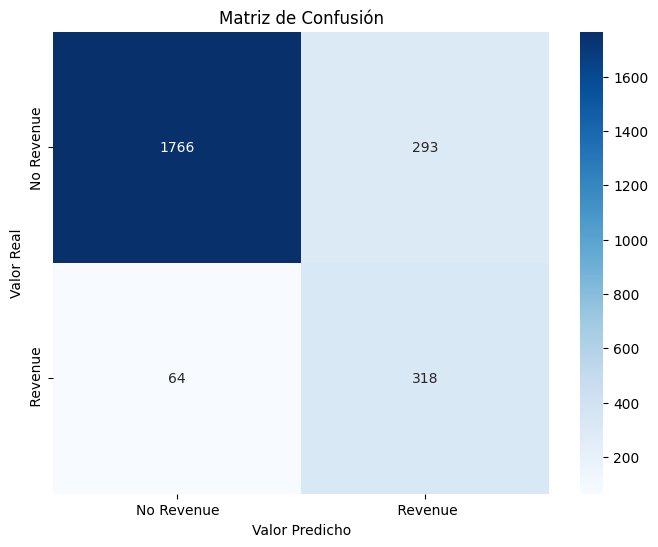

In [ ]:
y_pred_test = dt.predict(X_test_scaled)
metrics_score(y_test, y_pred_test, labels=["No Revenue", " Revenue"])

**Observaciones:**

- El árbol se entrenó con `class_weight={0:0.17, 1:0.83}`, Gini, `min_samples_leaf=10` y `min_impurity_decrease=0.001`; alcanzó profundidad 6 y 18 hojas.
- Detectó **318 de 382 compras (recall 83 %)**, el mejor recall de los modelos evaluados, con precisión 52 % y F1 0.64.
- En contrapartida generó 293 falsos positivos, frente a 167 de la logística con umbral 0.25.
- El accuracy baja a 85 %, lo que vuelve a mostrar que accuracy y recall priorizan cosas distintas bajo desbalance de clases.

In [ ]:
#Graficar las importancia de las variables y ver cuales son las mas importante
importances = pd.DataFrame({'feature':X.columns,'importance':np.round(dt.feature_importances_,3)})
importances = importances.sort_values('importance',ascending=False).set_index('feature')
importances

,importance
feature,
PageValues,0.821
Month_Nov,0.063
Trimestre_3,0.022
ProductRelated,0.022
Administrative_Duration,0.011
...,...
SpecialDay_0.2,0.000
SpecialDay_0.8,0.000
SpecialDay_0.6,0.000


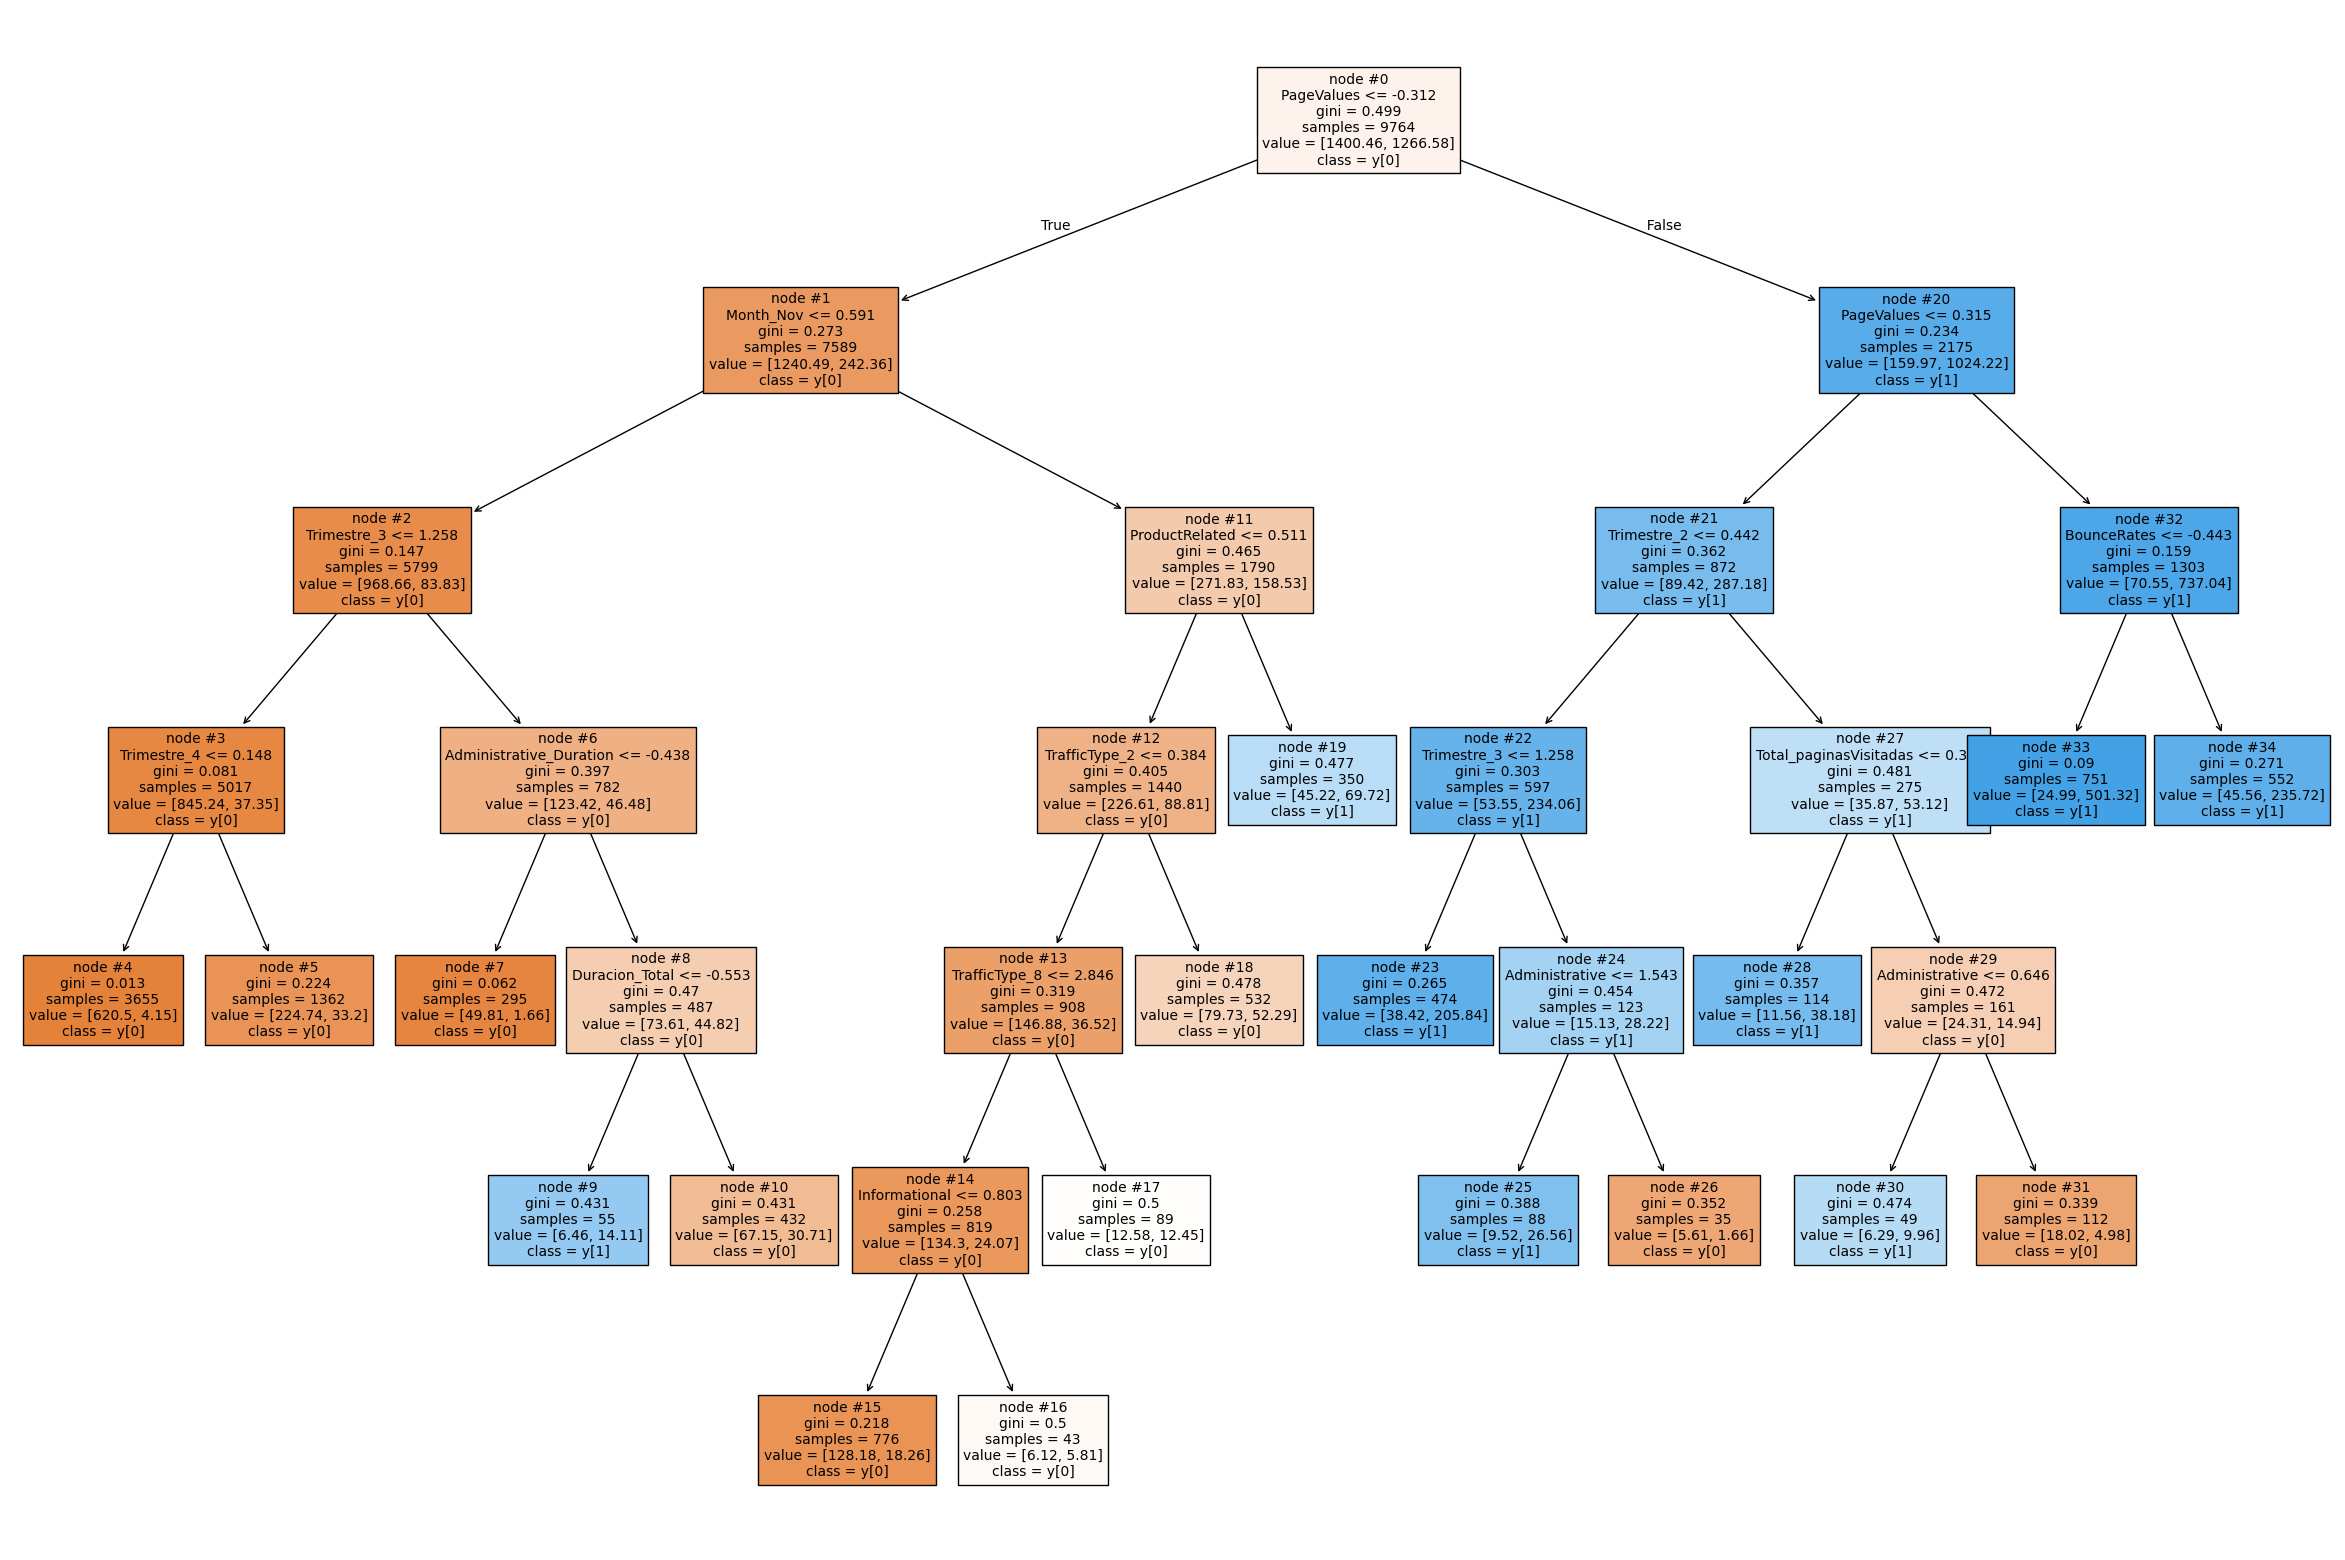

In [ ]:
feature_names = X_train.columns
plt.figure(figsize=(30,20))
tree.plot_tree(dt, feature_names=feature_names, filled=True, fontsize=10,  class_names=True, node_ids=True)
plt.show()

,Variable,Importancia
8,PageValues,0.8215
19,Month_Nov,0.0634
76,Trimestre_3,0.0224
4,ProductRelated,0.0222
1,Administrative_Duration,0.0107
11,Total_paginasVisitadas,0.0082
75,Trimestre_2,0.0080
0,Administrative,0.0076
49,TrafficType_2,0.0074
77,Trimestre_4,0.0068


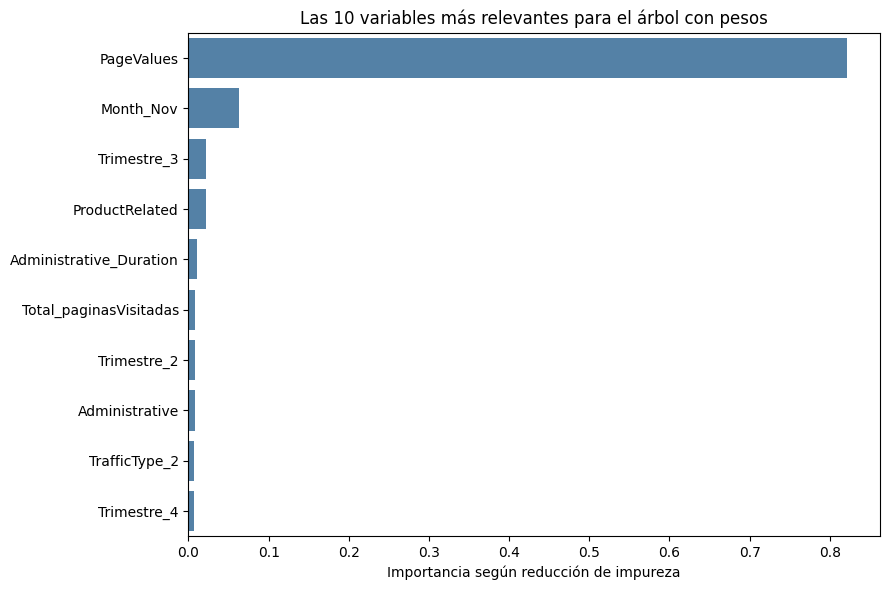

In [ ]:
importancias = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': dt.feature_importances_
})
importancias = importancias.sort_values('Importancia', ascending=False)

display(importancias.head(12).round(4))

plt.figure(figsize=(9, 6))
sns.barplot(data=importancias.head(10), x='Importancia', y='Variable', color='steelblue')
plt.title('Las 10 variables más relevantes para el árbol con pesos')
plt.xlabel('Importancia según reducción de impureza')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Observaciones:**

- `PageValues` concentra el **82.15 %** de la importancia del árbol, muy por encima de `Month_Nov` (6.34 %), `Trimestre_3` (2.24 %) y `ProductRelated` (2.22 %).
- Una sola variable domina las divisiones, por lo que el modelo es poco robusto si esa información no está disponible al momento de predecir.
- La importancia mide uso interno en las particiones y no demuestra causalidad.

[texto del vínculo](https://)# Maquina de vectores de soporte (SVM)

##Maquina de vectores de soporte
* Los modelos de Máquinas de Vectores de Soporte (SVM) son clasificadores potentes que separan las clases buscando una frontera óptima. Sin embargo, no todos los problemas son lineales

### ¿Qué es un Kernel?
Un kernel es una función matemática que permite proyectar los datos a un espacio de mayor dimensión, donde es más fácil encontrar una frontera de separación entre clases.

1. **Kernel lineal**
* Supone que las clases pueden separarse con una línea recta.
2. **Kernel RBF (Radial Basis Function)**
* Permite generar fronteras curvas y flexibles, adaptándose a distribuciones más complejas.

In [ ]:
# Función para graficar los límites de decisión
def plot_svm(model, X, y, ax, title):
    h = .02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.coolwarm)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.coolwarm)
    ax.set_title(title)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())

In [ ]:
#entrenar un SVM
svm = SVC(kernel='linear')
#svm = SVC(kernel='rbf')
svm.fit(X_train_scaled, y_train)

SVC(kernel='linear')


Reporte de clasificación:
              precision    recall  f1-score   support

  No Revenue       0.89      0.97      0.93      2059
     Revenue       0.69      0.38      0.49       382

    accuracy                           0.88      2441
   macro avg       0.79      0.67      0.71      2441
weighted avg       0.86      0.88      0.86      2441


Matriz de confusión:
[[1994   65]
 [ 238  144]]


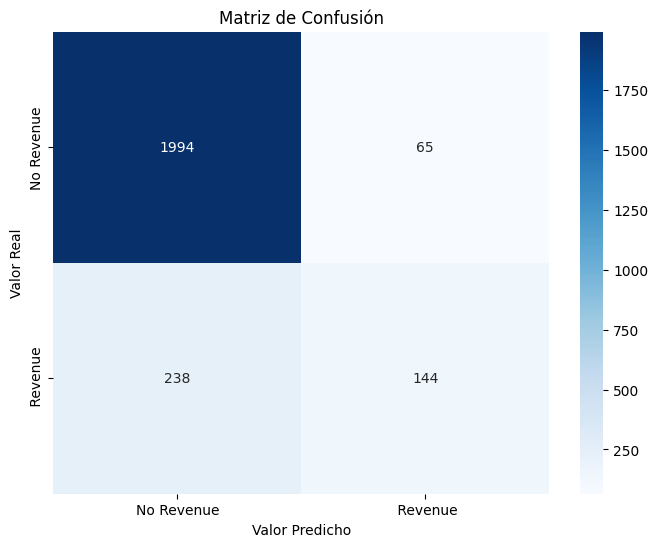

In [ ]:
y_pred_test_svm_lin = svm.predict(X_test_scaled)
metrics_score(y_test, y_pred_test_svm_lin, labels=["No Revenue", " Revenue"])

**Observaciones:**

- El SVM lineal obtuvo accuracy 88 %, similar al de la regresión logística con umbral 0.50.
- En compras solo alcanzó precisión 69 %, recall **38 %** y F1 0.49 (144 compras detectadas, 238 no detectadas), por lo que no supera al árbol ni a la logística con umbral 0.25.
- Bajo este desbalance de clases, el SVM con kernel lineal y configuración por defecto no aporta una ventaja frente a los modelos anteriores.

# Regresion lineal

In [ ]:
X_train = sm.add_constant(X_train, has_constant='add')
X_test = sm.add_constant(X_test, has_constant='add')

In [ ]:
# Crear una copia temporal de X_train para la eliminación hacia atrás
X_selected = X_train.copy()

# Agregar constante
#X = sm.add_constant(X, has_constant='add')

# Umbral de significancia (típicamente 0.05)
# quitar las varibles que no son tan significatibas
significance_level = 0.05

# Proceso iterativo de eliminación hacia atrás
while True:
    # Se ajusta un modelo de regresión lineal OLS (Ordinary Least Squares)
    #Busca una relación lineal entre una variable dependiente y y una o más variables independientes X.
    # Minimiza el error cuadrático total
    model = sm.OLS(y_train, X_selected).fit()
    p_values = model.pvalues
    max_pval = p_values.max()
    if max_pval > significance_level:
        excluded_variable = p_values.idxmax()
        print(f"Eliminando: {excluded_variable} (p={max_pval:.4f})")
        X_selected = X_selected.drop(columns=[excluded_variable])
    else:
        break

# Resultado final
print("\nResumen del modelo final:")
print(model.summary())
# la variable const se agrego para eliminar un poco la multicorrealinidad
# t es la prueba t de student, evalua el coeficiente


/tmp/ipykernel_3276/1201329172.py:16: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y_train, X_selected).fit()


Eliminando: TrafficType_12 (p=0.9924)


/tmp/ipykernel_3276/1201329172.py:16: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y_train, X_selected).fit()


Eliminando: Month_May (p=0.9793)


/tmp/ipykernel_3276/1201329172.py:16: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y_train, X_selected).fit()


Eliminando: ProductRelated_Duration (p=0.9521)


... (42 outputs left out)

/tmp/ipykernel_3276/1201329172.py:16: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y_train, X_selected).fit()


Eliminando: Month_Jul (p=0.6203)


/tmp/ipykernel_3276/1201329172.py:16: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y_train, X_selected).fit()
/tmp/ipykernel_3276/1201329172.py:16: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y_train, X_selected).fit()


Eliminando: Browser_7 (p=0.6231)
Eliminando: Month_Oct (p=0.5490)
Eliminando: SpecialDay_0.2 (p=0.5401)
Eliminando: Browser_5 (p=0.4936)
Eliminando: TrafficType_19 (p=0.4780)
Eliminando: TrafficType_15 (p=0.4415)
Eliminando: Trimestre_2 (p=0.4619)
Eliminando: SpecialDay_0.8 (p=0.4207)
Eliminando: Region_8 (p=0.4063)
Eliminando: Region_9 (p=0.3945)
Eliminando: TrafficType_7 (p=0.3788)
Eliminando: Browser_6 (p=0.3856)
Eliminando: Browser_3 (p=0.3785)
Eliminando: SpecialDay_0.4 (p=0.3425)
Eliminando: Region_4 (p=0.3287)
Eliminando: Region_3 (p=0.3495)
Eliminando: Region_7 (p=0.4009)
Eliminando: TrafficType_3 (p=0.3005)
Eliminando: Month_Sep (p=0.2477)
Eliminando: Informational_Duration (p=0.2241)
Eliminando: Administrative_Duration (p=0.2063)
Eliminando: Region_5 (p=0.2027)
Eliminando: Administrative (p=0.1860)
Eliminando: OperatingSystems_2 (p=0.1933)
Eliminando: Browser_12 (p=0.1278)
Eliminando: TrafficType_4 (p=0.1308)
Eliminando: TrafficType_5 (p=0.1608)
Eliminando: OperatingSystems_6

In [ ]:
residual = model.resid
fitted = model.fittedvalues

In [ ]:
#La media de los residuos es muy cercana a 0. Por tanto, se cumple la hipótesis correspondiente.
residual.mean()

np.float64(3.452034052118393e-14)

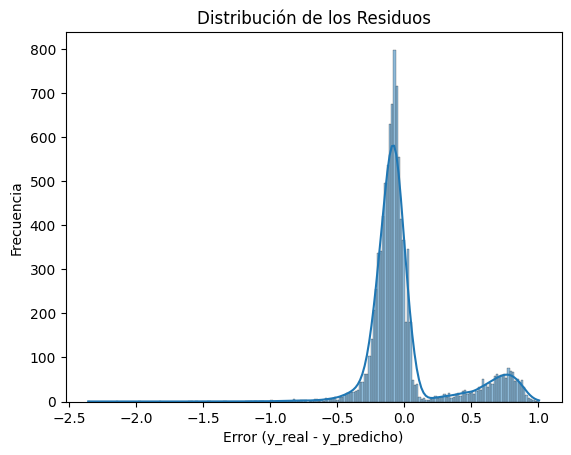

In [ ]:
sns.histplot(residual, kde=True)
plt.title("Distribución de los Residuos")
plt.xlabel("Error (y_real - y_predicho)")
plt.ylabel("Frecuencia")
plt.show()

In [ ]:
# Función para calcular el R cuadrado ajustado
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# función para calcular MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# Función para calcular diferentes métricas para comprobar el rendimiento de un modelo de regresión.
def model_performance_regression(model, predictors, target):
    """
    Función para calcular diferentes métricas para comprobar el rendimiento del modelo de regresión.

    Modelo: regresor
    Predictores: variables independientes
    Objetivo: variable dependiente
    """

    # predecir utilizando las variables independientes
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # tRMSE
    mae = mean_absolute_error(target, pred)  # MAE
    mape = mape_score(target, pred)  # MAPE

    # creando un marco de datos de métricas
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

# RMSE
def rmse(predictions, targets):
    return np.sqrt(((targets - predictions) ** 2).mean())


# MAPE
def mape(predictions, targets):
    return np.mean(np.abs((targets - predictions)) / targets) * 100


# MAE
def mae(predictions, targets):
    return np.mean(np.abs((targets - predictions)))


# Rendimiento del modelo en datos de prueba y entrenamiento
def model_pref(olsmodel, x_train, x_test, y_train,y_test):

    # Predicción en muestra
    y_pred_train = olsmodel.predict(x_train)
    y_observed_train = y_train

    # Predicción sobre datos de prueba
    y_pred_test = olsmodel.predict(x_test)
    y_observed_test = y_test

    print(
        pd.DataFrame(
            {
                "Data": ["Train", "Test"],
                "RMSE": [
                    rmse(y_pred_train, y_observed_train),
                    rmse(y_pred_test, y_observed_test),
                ],
                "MAE": [
                    mae(y_pred_train, y_observed_train),
                    mae(y_pred_test, y_observed_test),
                ],
                "MAPE": [
                    mape(y_pred_train, y_observed_train),
                    mape(y_pred_test, y_observed_test),
                ],
            }
        )
    )


In [ ]:
# 4. Ajustar X_test con las mismas columnas finales que X_selected
X_test_selected = X_test[X_selected.columns]

# 5. Evaluar el modelo con tu función model_performance_regression
# RMSE dice como por cuanto nos equivocamos en el valor real
#Mape el error porcentual

lin_reg_test = model_performance_regression(model, X_test_selected, y_test)
print("\nDesempeño del modelo en el conjunto de prueba:")
print(lin_reg_test)

ZeroDivisionError: float division by zero

In [ ]:
# Función para calcular el R cuadrado ajustado
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# función para calcular MAPE
def mape_score(targets, predictions):
    #return np.mean(np.abs(targets - predictions) / targets) * 100
    targets_safe = np.where(targets == 0, 1e-10, targets)
    return np.mean(np.abs(targets - predictions) / targets_safe) * 100


# Función para calcular diferentes métricas para comprobar el rendimiento de un modelo de regresión.
def model_performance_regression(model, predictors, target):
    """
    Función para calcular diferentes métricas para comprobar el rendimiento del modelo de regresión.

    Modelo: regresor
    Predictores: variables independientes
    Objetivo: variable dependiente
    """

    # predecir utilizando las variables independientes
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # tRMSE
    mae = mean_absolute_error(target, pred)  # MAE
    mape = mape_score(target, pred)  # MAPE

    # creando un marco de datos de métricas
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

# RMSE
def rmse(predictions, targets):
    return np.sqrt(((targets - predictions) ** 2).mean())


# MAPE
def mape(predictions, targets):
    #return np.mean(np.abs((targets - predictions)) / targets) * 100
    targets_safe = np.where(targets == 0, 1e-10, targets)
    return np.mean(np.abs((targets - predictions)) / targets_safe) * 100


# MAE
def mae(predictions, targets):
    return np.mean(np.abs((targets - predictions)))


# Rendimiento del modelo en datos de prueba y entrenamiento
def model_pref(olsmodel, x_train, x_test, y_train,y_test):

    # Predicción en muestra
    y_pred_train = olsmodel.predict(x_train)
    y_observed_train = y_train

    # Predicción sobre datos de prueba
    y_pred_test = olsmodel.predict(x_test)
    y_observed_test = y_test

    print(
        pd.DataFrame(
            {
                "Data": ["Train", "Test"],
                "RMSE": [
                    rmse(y_pred_train, y_observed_train),
                    rmse(y_pred_test, y_observed_test),
                ],
                "MAE": [
                    mae(y_pred_train, y_observed_train),
                    mae(y_pred_test, y_observed_test),
                ],
                "MAPE": [
                    mape(y_pred_train, y_observed_train),
                    mape(y_pred_test, y_observed_test),
                ],
            }
        )
    )


In [ ]:
# 4. Ajustar X_test con las mismas columnas finales que X_selected
X_test_selected = X_test[X_selected.columns]

# 5. Evaluar el modelo con tu función model_performance_regression
# RMSE dice como por cuanto nos equivocamos en el valor real
#Mape el error porcentual

lin_reg_test = model_performance_regression(model, X_test_selected, y_test)
print("\nDesempeño del modelo en el conjunto de prueba:")
print(lin_reg_test)


Desempeño del modelo en el conjunto de prueba:
     RMSE       MAE  R-squared  Adj. R-squared          MAPE
0  0.3082  0.202384   0.280416        0.275068  9.973922e+10


In [ ]:
model.params

,0
const,0.108388
BounceRates,0.564577
ExitRates,-1.076484
PageValues,0.008605
Total_paginasVisitadas,0.000439
Duracion_Total,0.000007
Month_Dec,-0.053690
Month_Nov,0.056853
OperatingSystems_3,-0.021353
TrafficType_2,0.027455


In [ ]:
# Creamos X_test_selected con las mismas columnas
X_test_selected = X_test[X_selected.columns]

# Crear y entrenar el modelo de regresión lineal
# este si aprende si es ML
#
lr = LinearRegression()
lr.fit(X_selected, y_train)

# Predecir los valores de MEDV para el conjunto de prueba
y_pred = lr.predict(X_test_selected)

In [ ]:
X_selected_pred = X_selected.copy()
X_selected_pred['medv'] = y_train
X_selected_pred['pred'] = lr.predict(X_selected)
X_selected_pred['error'] = X_selected_pred['pred'] - X_selected_pred['medv']
X_selected_pred

,const,BounceRates,ExitRates,PageValues,Total_paginasVisitadas,Duracion_Total,Month_Dec,Month_Nov,OperatingSystems_3,TrafficType_2,...,TrafficType_10,TrafficType_13,TrafficType_20,VisitorType_Other,VisitorType_Returning_Visitor,Trimestre_3,Trimestre_4,medv,pred,error
3904,1.0,0.014286,0.074286,0.000000,7,380.000000,False,False,False,False,...,False,False,False,False,True,False,False,False,0.008366,0.008366
10800,1.0,0.004545,0.022727,0.000000,22,348.500000,False,True,False,False,...,False,False,False,False,True,False,True,True,0.158949,-0.841051
9042,1.0,0.000000,0.025000,0.000000,8,650.250000,False,True,False,False,...,False,False,False,False,True,False,True,False,0.149909,0.149909
11598,1.0,0.008499,0.029697,0.000000,296,15601.424843,True,False,False,True,...,False,False,False,False,True,False,True,False,0.297946,0.297946
3650,1.0,0.000000,0.050000,0.000000,4,81.000000,False,False,False,False,...,False,False,False,False,True,False,False,False,0.023028,0.023028
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4011,1.0,0.008571,0.032381,11.694857,41,2313.472222,False,False,True,False,...,False,True,False,False,True,False,False,True,0.113273,-0.886727
2844,1.0,0.000000,0.019928,0.000000,23,996.438095,False,False,True,False,...,False,False,False,False,True,False,False,False,0.048815,0.048815
11885,1.0,0.000000,0.027778,0.000000,13,262.500000,True,False,False,True,...,False,False,False,False,True,False,True,False,0.063304,0.063304
7921,1.0,0.008889,0.022870,0.000000,133,4006.664774,False,True,True,False,...,False,False,False,False,True,False,True,False,0.214301,0.214301


In [ ]:
selected_features = X_selected.columns.drop("const", errors="ignore").tolist()

selected_features

['BounceRates',
 'ExitRates',
 'PageValues',
 'Total_paginasVisitadas',
 'Duracion_Total',
 'Month_Dec',
 'Month_Nov',
 'OperatingSystems_3',
 'TrafficType_2',
 'TrafficType_8',
 'TrafficType_10',
 'TrafficType_13',
 'TrafficType_20',
 'VisitorType_Other',
 'VisitorType_Returning_Visitor',
 'Trimestre_3',
 'Trimestre_4']

In [ ]:
# Modelo base: todas las variables, sin columna const
lr_base = LinearRegression()
lr_base.fit(X_train, y_train)
y_pred_base = lr_base.predict(X_test)

# Modelo con selección hacia atrás: exactamente las columnas elegidas por OLS
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]
lr_selected = LinearRegression()
lr_selected.fit(X_train_selected, y_train)
y_pred_selected = lr_selected.predict(X_test_selected)

print("Intercepto (modelo seleccionado):", lr_selected.intercept_)
display(pd.Series(lr_selected.coef_, index=selected_features, name="Coeficiente").to_frame())

Intercepto (modelo seleccionado): 0.1083880049539294


,Coeficiente
BounceRates,0.564577
ExitRates,-1.076484
PageValues,0.008605
Total_paginasVisitadas,0.000439
Duracion_Total,0.000007
Month_Dec,-0.053690
Month_Nov,0.056853
OperatingSystems_3,-0.021353
TrafficType_2,0.027455
TrafficType_8,0.080273


In [ ]:
def evaluar_regresion(y_real, y_estimado):
    mse = mean_squared_error(y_real, y_estimado)
    return {
        "MAE": mean_absolute_error(y_real, y_estimado),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_real, y_estimado)
    }

resultados = pd.DataFrame({
    "Lineal (todas las variables)": evaluar_regresion(y_test, y_pred_base),
    "Lineal (variables seleccionadas)": evaluar_regresion(y_test, y_pred_selected)
}).T
print("Evaluación sobre el conjunto de PRUEBA:")
display(resultados.round(4))

Evaluación sobre el conjunto de PRUEBA:


,MAE,MSE,RMSE,R²
Lineal (todas las variables),0.2027,0.0952,0.3086,0.2788
Lineal (variables seleccionadas),0.2024,0.0950,0.3082,0.2804


**Nota — experimento de regresión lineal descartado:**

- En este bloque la variable objetivo es `Revenue` (0/1), no una magnitud continua, por lo que sus métricas (R² 0.2804, MAE 0.2024, RMSE 0.3082) no son comparables con la regresión del proyecto.
- La selección hacia atrás conservó `PageValues` y variables derivadas de la duración, y el MAPE calculado no es interpretable con una respuesta binaria.
- Por estas razones este experimento no se considera definitivo. La regresión oficial es la de `RegresionLineal_Apriori_3.ipynb`, que estima `ProductRelated_Duration` en segundos (R² 0.6901 y MAE 501.31 s en prueba).

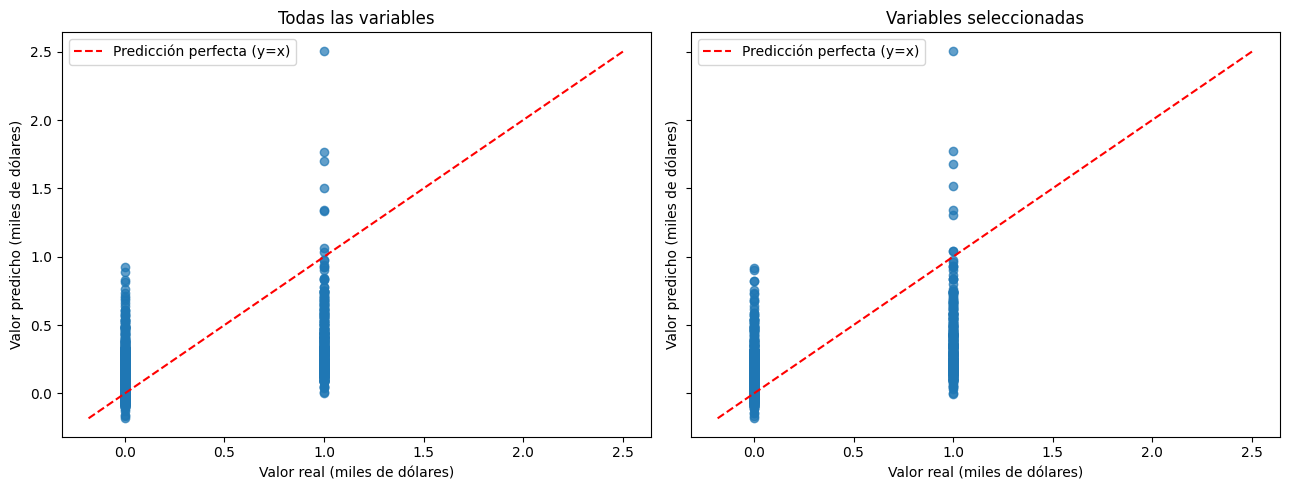

In [ ]:

# Comparación de valores reales frente a predichos: línea de identidad y=x
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
lims = [min(y_test.min(), y_pred_base.min(), y_pred_selected.min()),
        max(y_test.max(), y_pred_base.max(), y_pred_selected.max())]
for ax, pred, title in zip(
    axes,
    [y_pred_base, y_pred_selected],
    ["Todas las variables", "Variables seleccionadas"]
):
    ax.scatter(y_test, pred, alpha=0.7)
    ax.plot(lims, lims, "r--", label="Predicción perfecta (y=x)")
    ax.set_title(title)
    ax.set_xlabel("Valor real (miles de dólares)")
    ax.set_ylabel("Valor predicho (miles de dólares)")
    ax.legend()
plt.tight_layout()
plt.show()